# 1: Importar Cóigo Kaggle

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Path to dataset files:", path)

100%|██████████| 42.6M/42.6M [00:00<00:00, 80.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/olistbr/brazilian-ecommerce/versions/2


# 2: Importar Bibliotecas e Carregar as Planilhas

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual dos gráficos (estilo limpo para apresentação executiva)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# Listando os arquivos baixados automaticamente pelo kagglehub na variável 'path'
print("Arquivos disponíveis na pasta:", os.listdir(path))

# Carregando as tabelas principais (Etapa de Seleção de Dados - Metodologia KDD/CRISP-DM)
orders = pd.read_csv(os.path.join(path, "olist_orders_dataset.csv"))
items = pd.read_csv(os.path.join(path, "olist_order_items_dataset.csv"))
payments = pd.read_csv(os.path.join(path, "olist_order_payments_dataset.csv"))
reviews = pd.read_csv(os.path.join(path, "olist_order_reviews_dataset.csv"))
customers = pd.read_csv(os.path.join(path, "olist_customers_dataset.csv"))
products = pd.read_csv(os.path.join(path, "olist_products_dataset.csv"))

print(f"Total de pedidos carregados: {len(orders):,}")

Arquivos disponíveis na pasta: ['olist_geolocation_dataset.csv', 'product_category_name_translation.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_sellers_dataset.csv', 'olist_customers_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv']
Total de pedidos carregados: 99,441


# 3: Governança, Limpeza e Cruzamento das Tabelas

In [ ]:
# 1. Verificação de Governança: Estrutura e Dados Faltantes (NaN) na tabela de pedidos
print("--- INFORMAÇÕES DA TABELA DE PEDIDOS ---")
orders.info()
print("\n--- VALORES AUSENTES (NULOS) POR COLUNA ---")
print(orders.isna().sum())

# 2. Conversão de colunas de texto para formato de Data (Timestamp)
colunas_data = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in colunas_data:
    orders[col] = pd.to_datetime(orders[col])

# 3. Engenharia de Atributos (Feature Engineering): Criando indicadores logísticos (SLA)
# Tempo real de entrega em dias (Lead Time)
orders['tempo_entrega_dias'] = (orders['order_delivered_customer_date'] - orders['order_purchase_timestamp']).dt.total_seconds() / 86400

# Diferença entre a entrega real e a data prometida (valores positivos = atraso)
orders['diferenca_prazo_dias'] = (orders['order_delivered_customer_date'] - orders['order_estimated_delivery_date']).dt.total_seconds() / 86400

# Classificação binária: Entregue no Prazo vs. Atrasado
orders['status_prazo'] = np.where(orders['diferenca_prazo_dias'] > 0, 'Com Atraso', 'No Prazo')

# Safra mensal (Ano-Mês) para análise de evolução temporal
orders['ano_mes'] = orders['order_purchase_timestamp'].dt.to_period('M').astype(str)

# 4. Modelagem Dimensional: Unindo Fatos e Dimensões (Star Schema via pd.merge)
# Agrupando itens por pedido para obter valor total de produtos e frete por pedido
itens_por_pedido = items.groupby('order_id').agg(
    valor_produtos=('price', 'sum'),
    valor_frete=('freight_value', 'sum'),
    qtd_itens=('order_item_id', 'count')
).reset_index()
itens_por_pedido['receita_total_pedido'] = itens_por_pedido['valor_produtos'] + itens_por_pedido['valor_frete']

# Pegando a nota média de avaliação por pedido
reviews_por_pedido = reviews.groupby('order_id')['review_score'].mean().reset_index()

# Cruzando tudo em um DataFrame analítico único (filtrando pedidos efetivamente entregues)
df_olist = orders[orders['order_status'] == 'delivered'].copy()
df_olist = df_olist.merge(itens_por_pedido, on='order_id', how='inner')
df_olist = df_olist.merge(customers[['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']], on='customer_id', how='left')
df_olist = df_olist.merge(reviews_por_pedido, on='order_id', how='left')

# Removendo eventuais linhas sem data de entrega registrada
df_olist = df_olist.dropna(subset=['tempo_entrega_dias', 'receita_total_pedido'])

print(f"\nBase analítica consolidada pronta: {len(df_olist):,} pedidos entregues analisados.")
df_olist[['order_id', 'ano_mes', 'customer_state', 'receita_total_pedido', 'tempo_entrega_dias', 'status_prazo', 'review_score']].head()

--- INFORMAÇÕES DA TABELA DE PEDIDOS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

--- VALORES AUSENTES (NULOS) POR COLUNA ---
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at       

,order_id,ano_mes,customer_state,receita_total_pedido,tempo_entrega_dias,status_prazo,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10,SP,38.71,8.436574,No Prazo,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07,BA,141.46,13.782037,No Prazo,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08,GO,179.12,9.394213,No Prazo,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11,RN,72.20,13.208750,No Prazo,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02,SP,28.62,2.873877,No Prazo,5.0


# 4: Análise Estatística Completa (Tendência Central, Dispersão e Percentis)

In [ ]:
# Função para gerar o resumo estatístico completo das variáveis quantitativas (Escala de Razão)
def relatorio_estatistico(serie, nome_variavel):
    media = serie.mean()
    mediana = serie.median()
    moda = serie.mode().iloc[0]
    minimo = serie.min()
    maximo = serie.max()
    amplitude = maximo - minimo
    variancia = serie.var() # Variância amostral (ddof=1)
    desvio_padrao = serie.std() # Desvio-padrão amostral
    cv = (desvio_padrao / media) * 100 # Coeficiente de Variação (%)
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    p90 = serie.quantile(0.90)

    return pd.Series({
        'Média': round(media, 2),
        'Mediana (Q2)': round(mediana, 2),
        'Moda': round(moda, 2),
        'Mínimo': round(minimo, 2),
        'Máximo': round(maximo, 2),
        'Amplitude': round(amplitude, 2),
        'Variância (s²)': round(variancia, 2),
        'Desvio-Padrão (s)': round(desvio_padrao, 2),
        'Coef. Variação (CV %)': round(cv, 2),
        'IQR (Q3 - Q1)': round(iqr, 2),
        'Percentil 90 (P90)': round(p90, 2)
    }, name=nome_variavel)

# Calculando estatísticas para Receita do Pedido, Valor do Frete e Tempo de Entrega
tabela_estatistica = pd.concat([
    relatorio_estatistico(df_olist['receita_total_pedido'], 'Valor Total do Pedido (R$)'),
    relatorio_estatistico(df_olist['valor_frete'], 'Valor do Frete (R$)'),
    relatorio_estatistico(df_olist['tempo_entrega_dias'], 'Tempo de Entrega (Dias)')
], axis=1)

print("=== RESUMO ESTATÍSTICO EXECUTIVO (FASE 1) ===")
display(tabela_estatistica)

# Moda para variáveis Qualitativas (Nominal e Ordinal)
print("\n=== MODA DAS VARIÁVEIS QUALITATIVAS ===")
print("Estado (UF) mais frequente (Nominal):", df_olist['customer_state'].mode().values[0])
print("Meio de pagamento mais comum (Nominal):", payments['payment_type'].mode().values[0])
print("Nota de avaliação mais frequente (Ordinal):", df_olist['review_score'].mode().values[0])

=== RESUMO ESTATÍSTICO EXECUTIVO (FASE 1) ===


,Valor Total do Pedido (R$),Valor do Frete (R$),Tempo de Entrega (Dias)
Média,159.83,22.79,12.56
Mediana (Q2),105.28,17.17,10.22
Moda,77.57,15.10,2.07
Mínimo,9.59,0.00,0.53
Máximo,13664.08,1794.96,209.63
Amplitude,13654.49,1794.96,209.10
Variância (s²),47874.32,464.83,91.13
Desvio-Padrão (s),218.80,21.56,9.55
Coef. Variação (CV %),136.90,94.62,76.02
IQR (Q3 - Q1),114.41,10.17,8.95



=== MODA DAS VARIÁVEIS QUALITATIVAS ===
Estado (UF) mais frequente (Nominal): SP
Meio de pagamento mais comum (Nominal): credit_card
Nota de avaliação mais frequente (Ordinal): 5.0


# 5: Identificação de Outliers e Distribuição (Aula 06 de Estatística)

## 5.1: Boxplot de Outliers
Identifica visualmente os pontos fora da curva no tempo de entrega, utilizando a Regra do IQR (Interquartile Range).

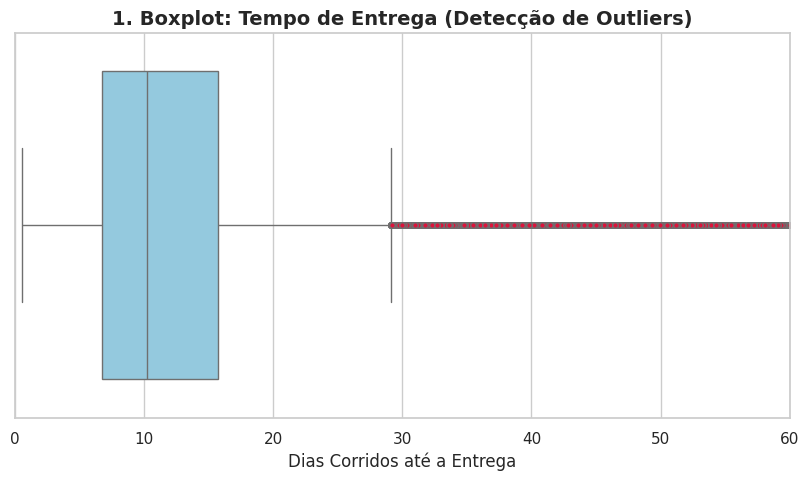

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df_olist['tempo_entrega_dias'], color='skyblue', flierprops=dict(markerfacecolor='crimson', marker='o', markersize=4))
plt.xlim(0, 60)
plt.title('1. Boxplot: Tempo de Entrega (Detecção de Outliers)', fontsize=14, fontweight='bold')
plt.xlabel('Dias Corridos até a Entrega')
plt.show()

## 5.2: Histograma de Distribuição
Prova a assimetria positiva (cauda longa à direita) dos dados logísticos, justificando o uso da Mediana em vez da Média para a apresentação aos investidores.

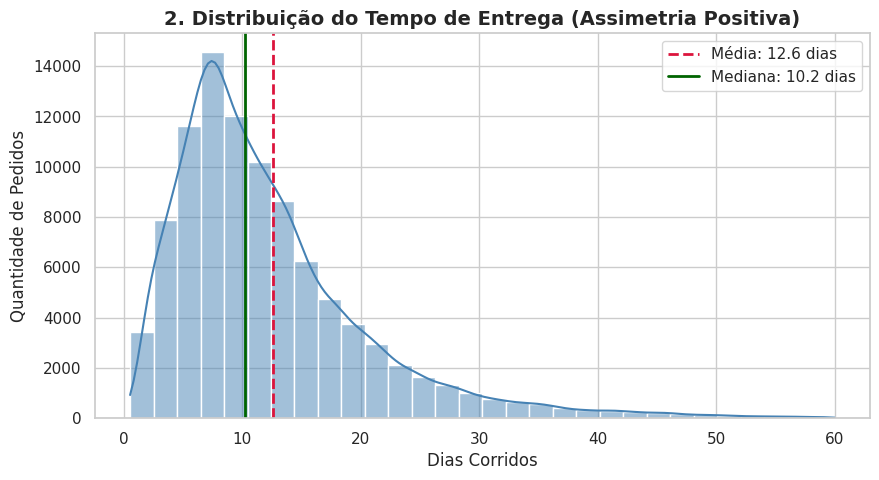

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(df_olist[df_olist['tempo_entrega_dias'] <= 60]['tempo_entrega_dias'], bins=30, kde=True, color='steelblue')
plt.axvline(df_olist['tempo_entrega_dias'].mean(), color='crimson', linestyle='--', linewidth=2, label=f"Média: {df_olist['tempo_entrega_dias'].mean():.1f} dias")
plt.axvline(df_olist['tempo_entrega_dias'].median(), color='darkgreen', linestyle='-', linewidth=2, label=f"Mediana: {df_olist['tempo_entrega_dias'].median():.1f} dias")
plt.title('2. Distribuição do Tempo de Entrega (Assimetria Positiva)', fontsize=14, fontweight='bold')
plt.xlabel('Dias Corridos')
plt.ylabel('Quantidade de Pedidos')
plt.legend()
plt.show()

# 6: Os 4 Gráficos Executivos para o Storytelling dos Investidores

## 6.1: Crescimento de Receita (Exposição / Ascensão)
Gráfico de linhas ideal para mostrar a tendência temporal e o crescimento de adoção do e-commerce.

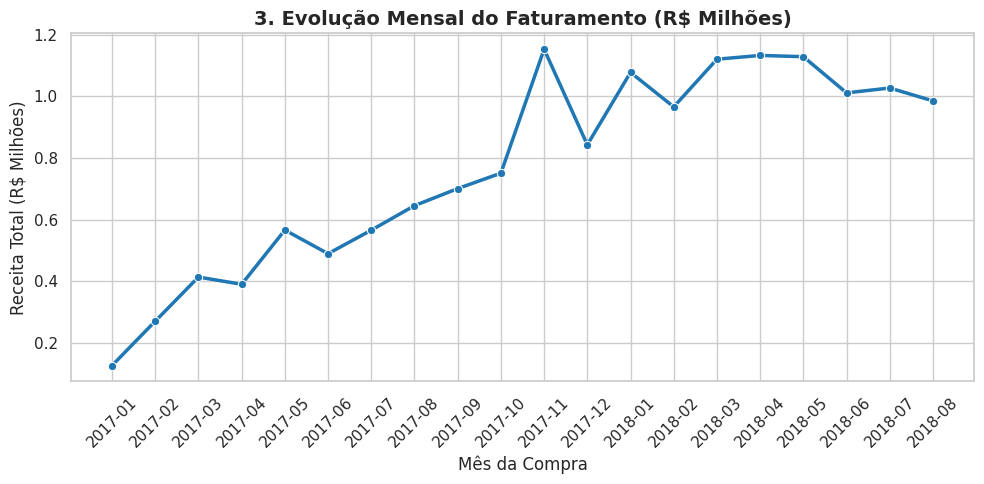

In [ ]:
plt.figure(figsize=(10, 5))
df_mensal = df_olist[(df_olist['ano_mes'] >= '2017-01') & (df_olist['ano_mes'] <= '2018-08')].groupby('ano_mes').agg(
    receita_milhoes=('receita_total_pedido', lambda x: x.sum() / 1e6),
    pedidos=('order_id', 'count')
).reset_index()

sns.lineplot(data=df_mensal, x='ano_mes', y='receita_milhoes', marker='o', linewidth=2.5, color='#1f77b4')
plt.title('3. Evolução Mensal do Faturamento (R$ Milhões)', fontsize=14, fontweight='bold')
plt.xlabel('Mês da Compra')
plt.ylabel('Receita Total (R$ Milhões)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6.2: Impacto do Atraso (O Conflito / Clímax)
Utiliza contraste de cores (verde vs. vermelho) para destacar o problema central: o descumprimento do prazo destrói a avaliação do cliente.

/tmp/ipykernel_1368/2583551490.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  barras = sns.barplot(data=nota_por_prazo, x='status_prazo', y='review_score', palette=cores_prazo)


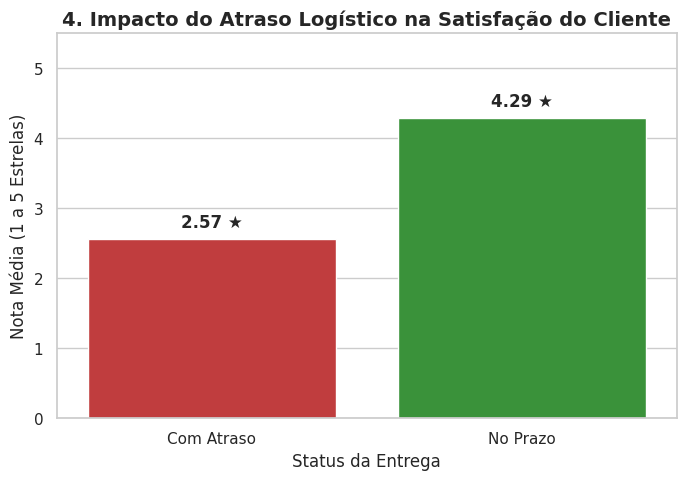

In [ ]:
plt.figure(figsize=(8, 5))
nota_por_prazo = df_olist.groupby('status_prazo')['review_score'].mean().reset_index()
cores_prazo = {'No Prazo': '#2ca02c', 'Com Atraso': '#d62728'}
barras = sns.barplot(data=nota_por_prazo, x='status_prazo', y='review_score', palette=cores_prazo)
plt.title('4. Impacto do Atraso Logístico na Satisfação do Cliente', fontsize=14, fontweight='bold')
plt.xlabel('Status da Entrega')
plt.ylabel('Nota Média (1 a 5 Estrelas)')
plt.ylim(0, 5.5)

for p in barras.patches:
    barras.annotate(f'{p.get_height():.2f} ★', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=12, fontweight='bold', xytext=(0, 5), textcoords='offset points')
plt.show()

## 6.3: Top 10 Estados (Apoio Analítico)
Gráfico de barras focado em comparações categóricas para evidenciar a concentração regional de vendas (Sudeste).

/tmp/ipykernel_1368/2016623704.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=uf_stats, x='receita_milhoes', y='customer_state', palette='Blues_r')


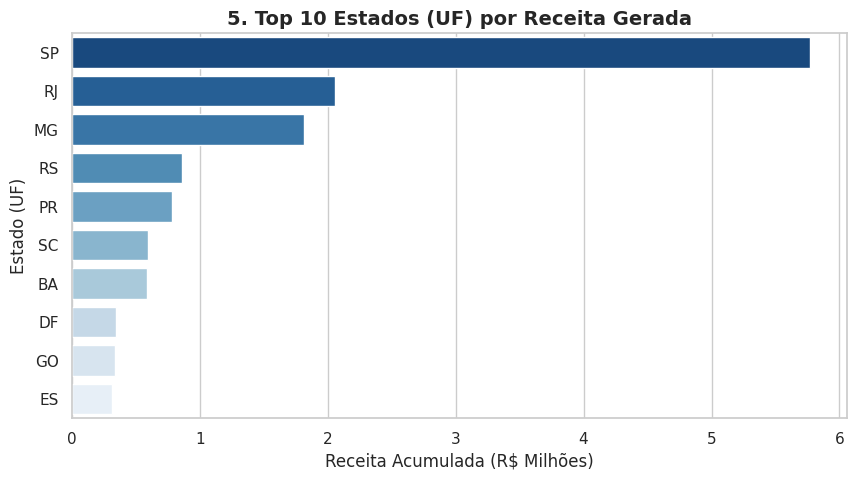

In [ ]:
plt.figure(figsize=(10, 5))
uf_stats = df_olist.groupby('customer_state').agg(
    receita_milhoes=('receita_total_pedido', lambda x: x.sum() / 1e6)
).sort_values(by='receita_milhoes', ascending=False).head(10).reset_index()

sns.barplot(data=uf_stats, x='receita_milhoes', y='customer_state', palette='Blues_r')
plt.title('5. Top 10 Estados (UF) por Receita Gerada', fontsize=14, fontweight='bold')
plt.xlabel('Receita Acumulada (R$ Milhões)')
plt.ylabel('Estado (UF)')
plt.show()

## 6.4: Meios de Pagamento (Comportamento)

/tmp/ipykernel_1368/223909530.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  eixos = sns.barplot(x=pagamentos_resumo.values, y=pagamentos_resumo.index, palette='viridis')


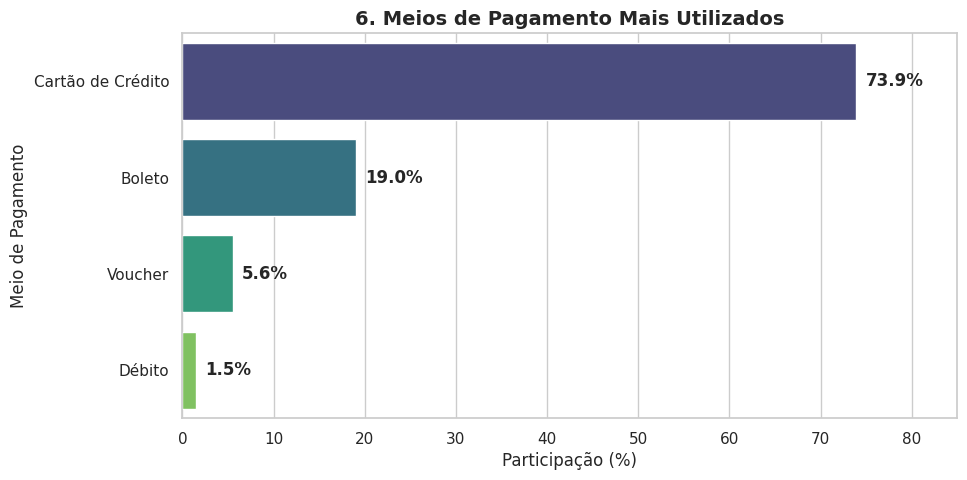

In [ ]:
plt.figure(figsize=(10, 5))
pagamentos_resumo = payments['payment_type'].value_counts(normalize=True).head(4) * 100
nomes_pag = {'credit_card': 'Cartão de Crédito', 'boleto': 'Boleto', 'voucher': 'Voucher', 'debit_card': 'Débito'}
pagamentos_resumo.index = [nomes_pag.get(x, x) for x in pagamentos_resumo.index]

eixos = sns.barplot(x=pagamentos_resumo.values, y=pagamentos_resumo.index, palette='viridis')
plt.title('6. Meios de Pagamento Mais Utilizados', fontsize=14, fontweight='bold')
plt.xlabel('Participação (%)')
plt.ylabel('Meio de Pagamento')
plt.xlim(0, 85)

for i, v in enumerate(pagamentos_resumo.values):
    plt.text(v + 1, i, f'{v:.1f}%', va='center', fontweight='bold')
plt.show()